<table style="width: 100%; border-collapse: collapse; border: none; background-color: transparent;">
  <tr style="border: none;">
    <td style="width: 20%; border: none; text-align: center;">
      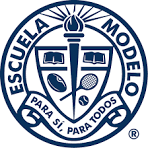
    </td>
    <td style="width: 60%; border: none; text-align: center;">
      <h2 style="margin: 0; font-family: sans-serif;">Tecnologico de Merida</h2>
      <h3 style="margin: 5px 0; color: #4a4a4a; font-family: sans-serif;">Taller: Deep Learning para Procesamiento de Imágenes Médicas</h3>
      <p style="margin: 15px 0 5px 0; font-size: 16px; font-family: sans-serif;">
        <b>Impartido por:</b><br>
        Br.Jorge Alejandro Chávez Gómez<br>
        Ing. Ismael Pérez Ruiz
      </p>
      <p style="margin: 0; font-style: italic; font-size: 14px; font-family: sans-serif;">
        Mérida, Yucatán — Noviembre 2026
      </p>
    </td>
    <td style="width: 20%; border: none; text-align: center;">
      <img src="https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcQiyAYL5D1aU2YCON9_9-Y7IrNbXvE4d5inz0zvPzJQwA&s" alt="Logo HRAEPY" width="130">
    </td>
  </tr>
</table>
<hr style="border: 1px solid #ccc;">

## Clasificacion BloodMnist

## Descargar y cargar dataset (MedMNIST)
Este dataset contiene imágenes de distintos tamaños de diferentes imágenes médicas, en este caso utilizaremos el set de datos de histopatología.

El set de datos original proviene de Andres Acevedo et al (2020). En el set de datos MedMNIST en su GitHub se da las siguientes etiquetas:


```
"0": "basophil",
"1": "eosinophil",
"2": "erythroblast",
"3": "immature granulocytes(myelocytes, metamyelocytes and promyelocytes)",
"4": "lymphocyte",
"5": "monocyte",
"6": "neutrophil",
"7": "platelet",
```





In [1]:
import os
import urllib.request
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers,models

In [2]:
url_dataset = "https://zenodo.org/records/10519652/files/bloodmnist.npz"
local = "bloodmnist.npz"

if not os.path.exists(local):
  print("Descargando...")
  urllib.request.urlretrieve(url_dataset, local)
  print("Completado")

Descargando...
Completado


In [3]:
# Cargar datos
data = np.load(local)
print(data['train_labels'])

[[7]
 [3]
 [6]
 ...
 [1]
 [6]
 [4]]


In [4]:
from collections import Counter

counter_labels = Counter(data['train_labels'].flatten())

print("Distribución de etiquetas en el set de entrenamiento:")
for label, total in sorted(counter_labels.items()):
    print(f"Clase {label}: {total} imágenes")

Distribución de etiquetas en el set de entrenamiento:
Clase 0: 852 imágenes
Clase 1: 2181 imágenes
Clase 2: 1085 imágenes
Clase 3: 2026 imágenes
Clase 4: 849 imágenes
Clase 5: 993 imágenes
Clase 6: 2330 imágenes
Clase 7: 1643 imágenes


In [5]:
# Análisis de set de datos
train = len(data['train_images'])
val = len(data['val_images'])
test = len(data['test_images'])
total = train + val + test

print(f"Imágenes totales: {total} ({train} Train, {val} Val, {test} Test)")

Imágenes totales: 17092 (11959 Train, 1712 Val, 3421 Test)


In [6]:
# Extraer unas cuantas imagenes
images = data['train_images'][:2500]
labels = data['train_labels'][:2500].flatten()
train_labels = data['train_labels'].flatten()
val_labels = data['val_labels'].flatten()
test_labels = data['test_labels'].flatten()
q, h, w, c = images.shape
print(f"Dataset cargado: {q} imágenes de {h}x{w} píxeles y {c} dimensiones (RGB)")

Dataset cargado: 2500 imágenes de 28x28 píxeles y 3 dimensiones (RGB)


In [7]:
counter_labels = Counter(data['train_labels'][:2500].flatten())

print("Distribución de etiquetas en el set de entrenamiento:")
for label, total in sorted(counter_labels.items()):
    print(f"Clase {label}: {total} imágenes")

Distribución de etiquetas en el set de entrenamiento:
Clase 0: 183 imágenes
Clase 1: 435 imágenes
Clase 2: 229 imágenes
Clase 3: 446 imágenes
Clase 4: 169 imágenes
Clase 5: 214 imágenes
Clase 6: 496 imágenes
Clase 7: 328 imágenes


<h1>EDA</h1>

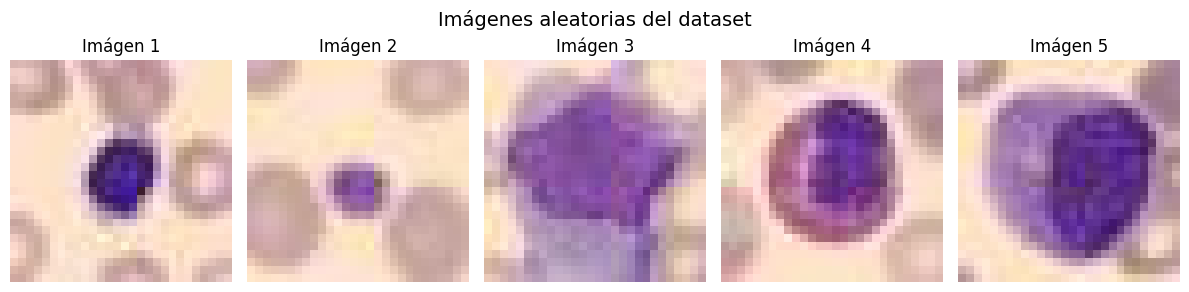

In [8]:
# Graficar imágenes al azar
random_indexes = np.random.choice(q, 5, replace=False)

fig1, axes1 = plt.subplots(1, 5, figsize=(12, 3))
fig1.suptitle("Imágenes aleatorias del dataset", fontsize=14)

for i, idx in enumerate(random_indexes):
  axes1[i].imshow(images[idx])
  axes1[i].set_title(f"Imágen {i + 1}")
  axes1[i].axis('off')

plt.tight_layout()
plt.show()

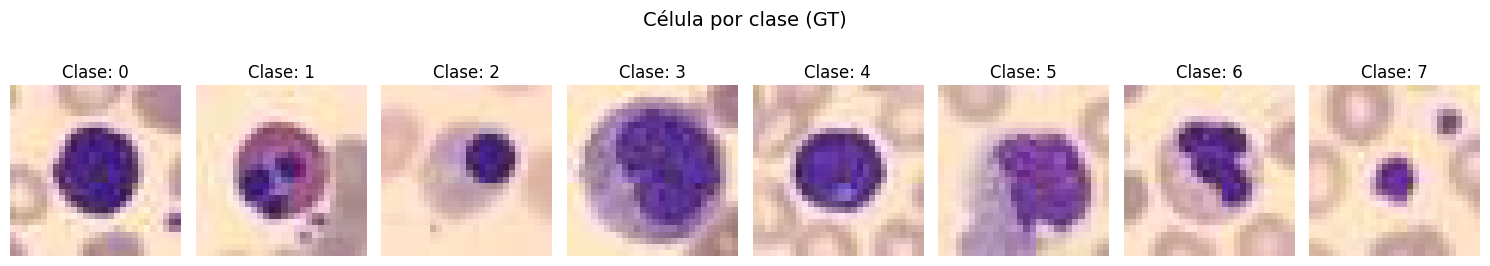

In [9]:
# Graficar imágen por clase
unique_classes = np.unique(labels)
num_classes = len(unique_classes)

fig2, axes2 = plt.subplots(1, num_classes, figsize=(15, 3))
fig2.suptitle("Célula por clase (GT)", fontsize=14)

for i, label in enumerate(unique_classes):
  idx_class = np.where(labels == label)[0][0]

  axes2[i].imshow(images[idx_class])
  axes2[i].set_title(f"Clase: {label}")
  axes2[i].axis('off')

plt.tight_layout()
plt.show()

In [10]:
train_images = data['train_images'] / 255.0
val_images = data['val_images'] / 255.0
test_images = data['test_images'] / 255.0

train_labels = data['train_labels'].flatten()
val_labels = data['val_labels'].flatten()
test_labels = data['test_labels'].flatten()

print(f"Forma de train_images: {train_images.shape}")

Forma de train_images: (11959, 28, 28, 3)


In [11]:
inputs = keras.Input(shape=(28, 28, 3))

x = layers.Conv2D(32, (3,3), activation='relu', name='conv_1')(inputs)
x = layers.MaxPooling2D((2,2), name='pool_1')(x)

x = layers.Conv2D(64, (3,3), activation='relu', name='conv_2')(x)
x = layers.MaxPooling2D((2,2), name='pool_2')(x)

x = layers.Conv2D(64, (3,3), activation='relu', name='conv_3')(x)

x = layers.Flatten()(x)
x = layers.Dense(64, activation='relu')(x)
outputs = layers.Dense(10, activation='softmax')(x)

model = keras.Model(inputs=inputs, outputs=outputs)

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()



Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 28, 28, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_1 (Conv2D)                 │ (None, 26, 26, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_1 (MaxPooling2D)           │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_2 (Conv2D)                 │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_2 (MaxPooling2D)           │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_3 (Conv2D)                 │ (None, 3, 3, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 576)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 93,898 (366.79 KB)

 Trainable params: 93,898 (366.79 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
model.fit(
    train_images, train_labels,
    epochs=5,
    validation_data=(test_images, test_labels)
)

Epoch 1/5
374/374 ━━━━━━━━━━━━━━━━━━━━ 19s 25ms/step - accuracy: 0.6046 - loss: 1.0953 - val_accuracy: 0.7279 - val_loss: 0.7530
Epoch 2/5
374/374 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7356 - loss: 0.7235 - val_accuracy: 0.7223 - val_loss: 0.7387
Epoch 3/5
374/374 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7737 - loss: 0.6257 - val_accuracy: 0.7995 - val_loss: 0.5562
Epoch 4/5
374/374 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7981 - loss: 0.5492 - val_accuracy: 0.8293 - val_loss: 0.4800
Epoch 5/5
374/374 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8328 - loss: 0.4691 - val_accuracy: 0.8270 - val_loss: 0.4995


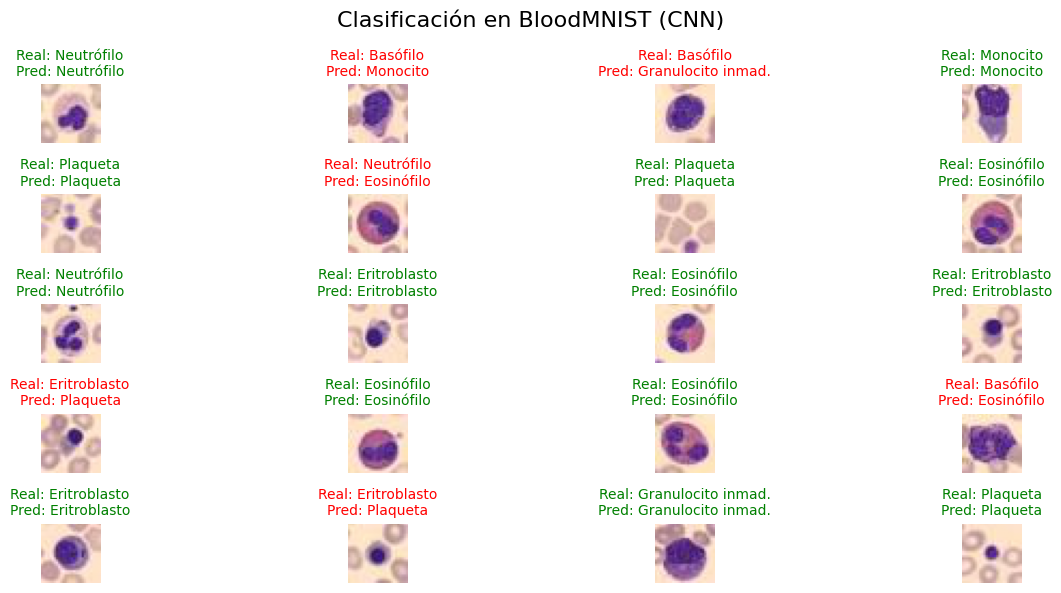

In [13]:
class_names = [
    'Basófilo', 'Eosinófilo', 'Eritroblasto', 'Granulocito inmad.',
    'Linfocito', 'Monocito', 'Neutrófilo', 'Plaqueta'
]

num_images = 20
indices = np.random.choice(len(test_images), num_images, replace=False)

plt.figure(figsize=(14, 6))
for i, idx in enumerate(indices):
    img = test_images[idx]
    true_label = test_labels[idx]  # Sin el [0] porque test_labels ya es 1D

    pred = model.predict(img[np.newaxis, ...], verbose=0)
    pred_label = np.argmax(pred)

    plt.subplot(5, 4, i + 1)
    plt.imshow(img)
    plt.axis('off')

    color = 'green' if pred_label == true_label else 'red'
    plt.title(
        f"Real: {class_names[true_label]}\n"
        f"Pred: {class_names[pred_label]}",
        color=color,
        fontsize=10
    )

plt.suptitle("Clasificación en BloodMNIST (CNN)", fontsize=16)
plt.tight_layout()
plt.show()

In [14]:
conv_layers = [
    layer for layer in model.layers
    if isinstance(layer, (layers.Conv2D, layers.MaxPooling2D))
]

activation_model = keras.Model(
    inputs=model.input,
    outputs=[layer.output for layer in conv_layers]
)

In [15]:
activations = activation_model.predict(img[np.newaxis, ...])

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 662ms/step


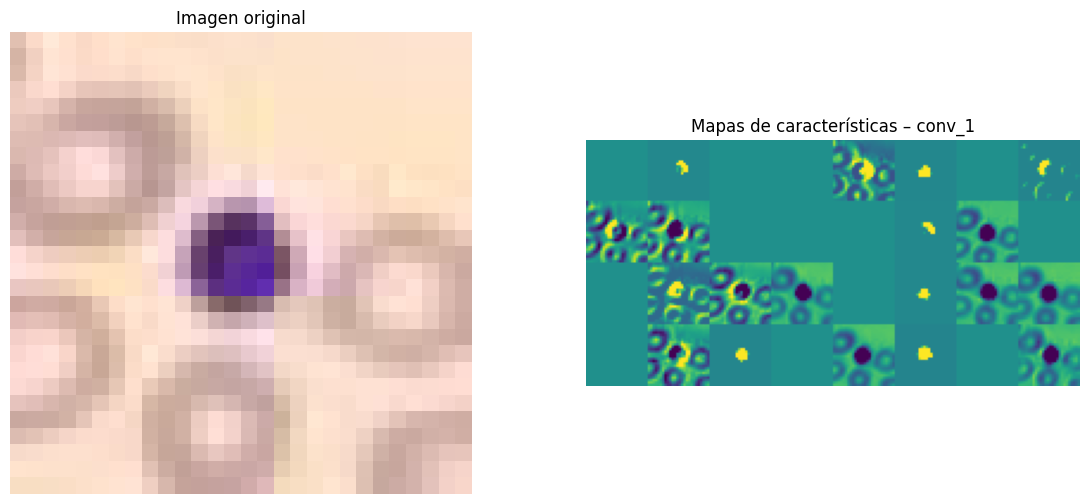

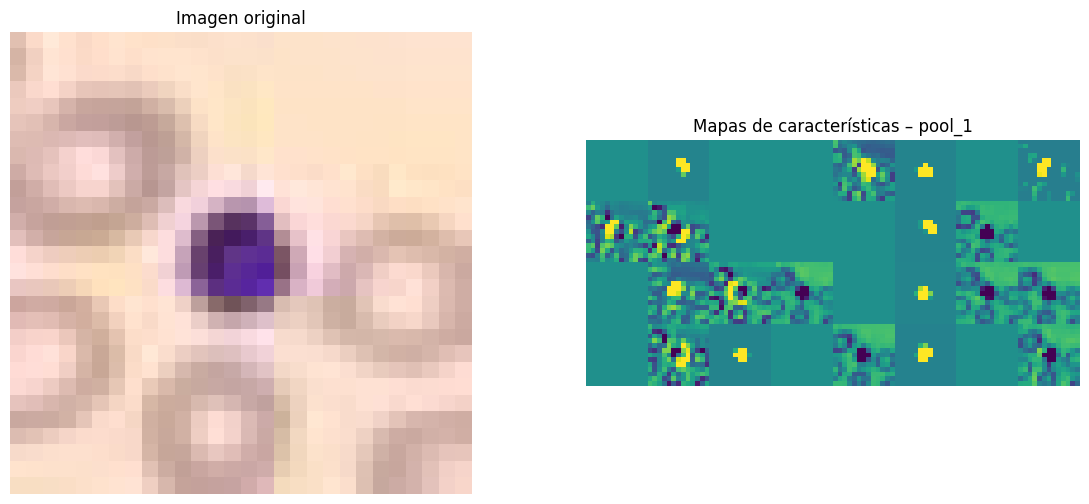

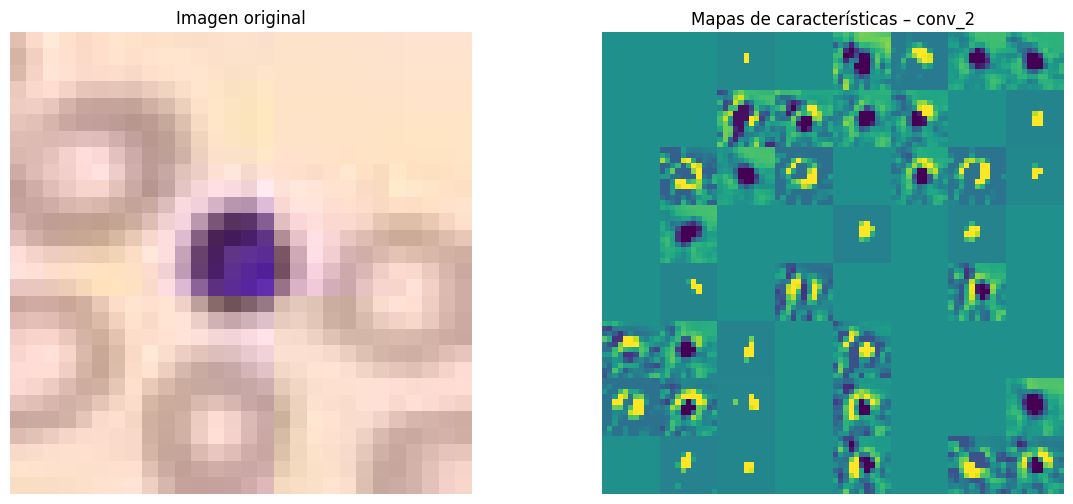

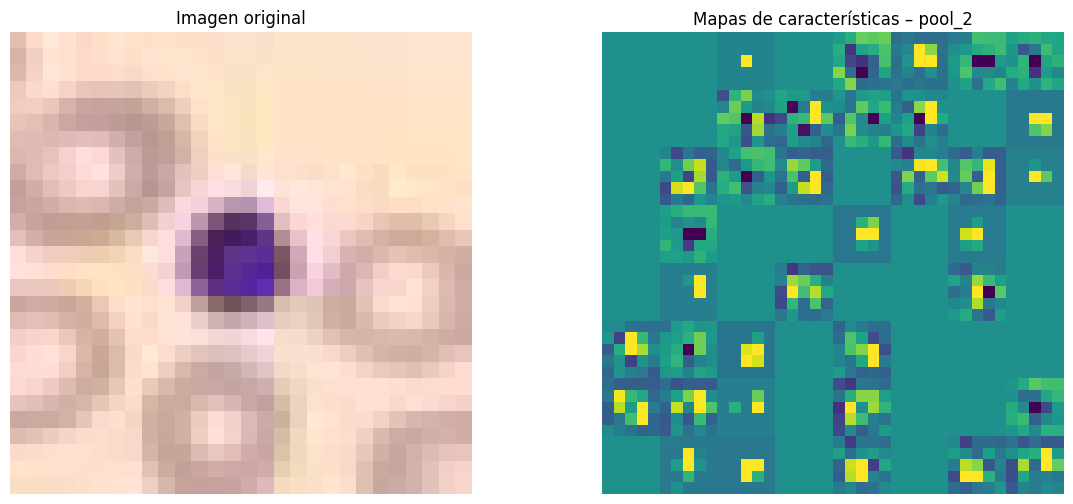

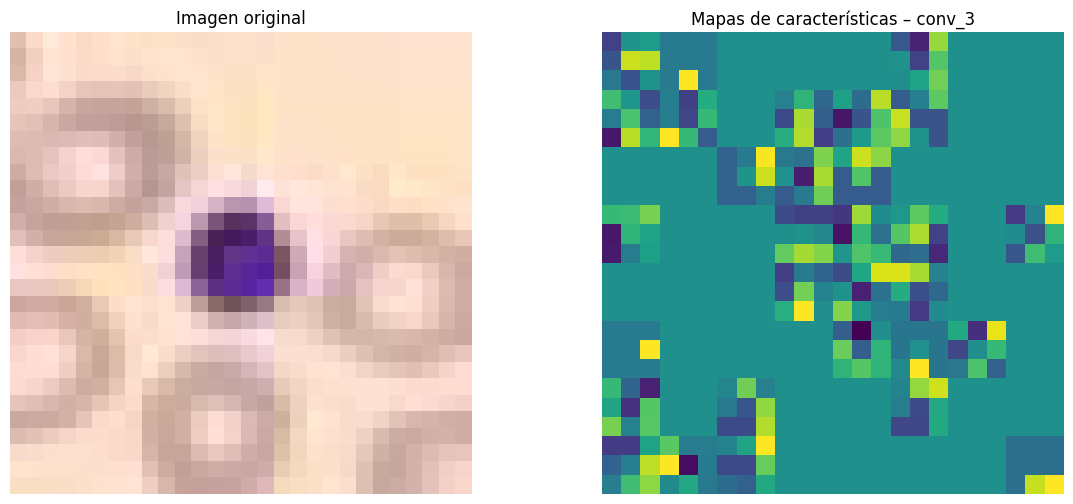

In [16]:
for layer, activation in zip(conv_layers, activations):

    n_features = activation.shape[-1]
    size = activation.shape[1]

    n_cols = n_features // 8
    display_grid = np.zeros((size * n_cols, 8 * size))

    for col in range(n_cols):
        for row in range(8):
            channel = activation[0, :, :, col * 8 + row]
            channel -= channel.mean()
            channel /= (channel.std() + 1e-5)
            channel = channel * 64 + 128
            channel = np.clip(channel, 0, 255)

            display_grid[
                col * size : (col + 1) * size,
                row * size : (row + 1) * size
            ] = channel

    plt.figure(figsize=(14, 6))

    # Imagen original
    plt.subplot(1, 2, 1)
    plt.imshow(img)
    plt.title("Imagen original")
    plt.axis('off')

    # Mapas de características
    plt.subplot(1, 2, 2)
    plt.imshow(display_grid, cmap='viridis')
    plt.title(f"Mapas de características – {layer.name}")
    plt.axis('off')

    plt.show()



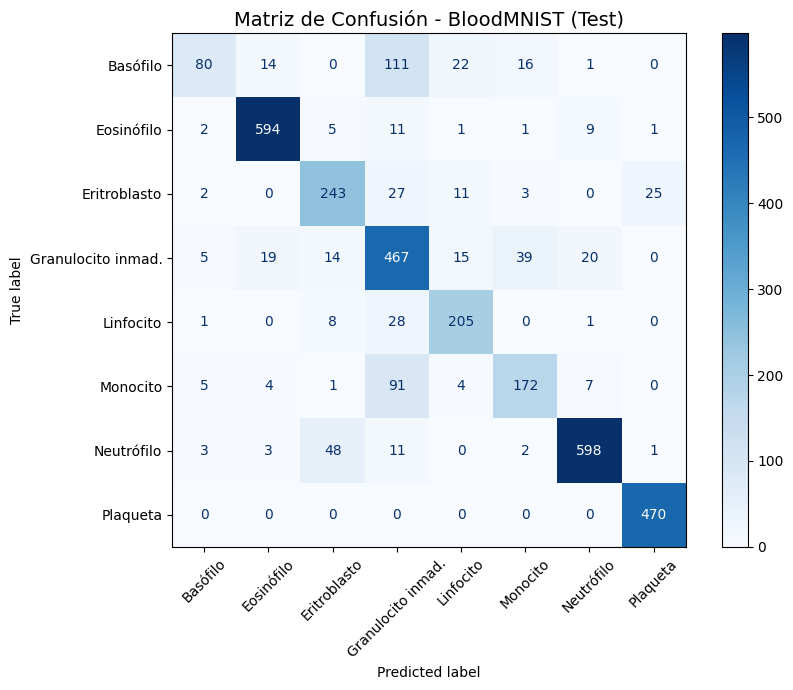


Reporte de Clasificación:

                    precision    recall  f1-score   support

          Basófilo     0.8163    0.3279    0.4678       244
        Eosinófilo     0.9369    0.9519    0.9444       624
      Eritroblasto     0.7618    0.7814    0.7714       311
Granulocito inmad.     0.6260    0.8066    0.7049       579
         Linfocito     0.7946    0.8436    0.8184       243
          Monocito     0.7382    0.6056    0.6654       284
        Neutrófilo     0.9403    0.8979    0.9186       666
          Plaqueta     0.9457    1.0000    0.9721       470

          accuracy                         0.8270      3421
         macro avg     0.8200    0.7769    0.7829      3421
      weighted avg     0.8350    0.8270    0.8208      3421



In [19]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

y_pred_probs = model.predict(test_images, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)

cm = confusion_matrix(test_labels, y_pred)

fig, ax = plt.subplots(figsize=(9, 7))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(cmap='Blues', ax=ax, xticks_rotation=45, values_format='d')

plt.title("Matriz de Confusión - BloodMNIST (Test)", fontsize=14)
plt.tight_layout()
plt.show()

print("\nReporte de Clasificación:\n")
print(classification_report(test_labels, y_pred, target_names=class_names, digits=4))